In [3]:
import pandas as pd
import numpy as np

# Load CSV without headers
file_path = 'EIS_Bat12.csv'
df = pd.read_csv(file_path, header=None)

# Convert string values to complex numbers
def str_to_complex(s):
    s = s.replace('i', 'j')
    return complex(s)

impedance_data = df.applymap(str_to_complex)
print("✅ Loaded impedance data:", impedance_data.shape)

# Extract imaginary parts for each element (|Im(Z)|)
imag_part = impedance_data.applymap(lambda z: abs(z.imag))

# Capacitance (from paper)
C = 1.042e-6  # Farads

# Estimate frequency for each point using: f = 1 / (2π Xc C)
frequency_matrix = 1 / (2 * np.pi * imag_part * C)

# Save full frequency matrix (optional)
frequency_matrix.to_csv("EIS_Bat12_Frequency_Matrix.csv", index=False)
print("✅ Frequency matrix saved as 'EIS_Bat12_Frequency_Matrix.csv'")

# (Optional) Save magnitude matrix too
magnitude_matrix = impedance_data.applymap(lambda z: abs(z))
magnitude_matrix.to_csv("EIS_Bat12_Magnitude_Matrix.csv", index=False)
print("✅ Magnitude matrix saved as 'EIS_Bat12_Magnitude_Matrix.csv'")

# Preview one row (optional)
print("\n🔍 Sample Frequency Row:")
print(frequency_matrix.iloc[0])

✅ Loaded impedance data: (14, 10)
✅ Frequency matrix saved as 'EIS_Bat12_Frequency_Matrix.csv'
✅ Magnitude matrix saved as 'EIS_Bat12_Magnitude_Matrix.csv'

🔍 Sample Frequency Row:
0    3.749977e+07
1    3.155748e+07
2    2.891330e+07
3    2.836734e+07
4    3.631567e+07
5    4.509624e+07
6    5.187117e+07
7    5.006617e+07
8    4.857384e+07
9    3.834177e+07
Name: 0, dtype: float64


C:\Users\Hp\AppData\Local\Temp\ipykernel_14304\2262434216.py:13: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  impedance_data = df.applymap(str_to_complex)
C:\Users\Hp\AppData\Local\Temp\ipykernel_14304\2262434216.py:17: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  imag_part = impedance_data.applymap(lambda z: abs(z.imag))
C:\Users\Hp\AppData\Local\Temp\ipykernel_14304\2262434216.py:30: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  magnitude_matrix = impedance_data.applymap(lambda z: abs(z))


Nyquist Plot

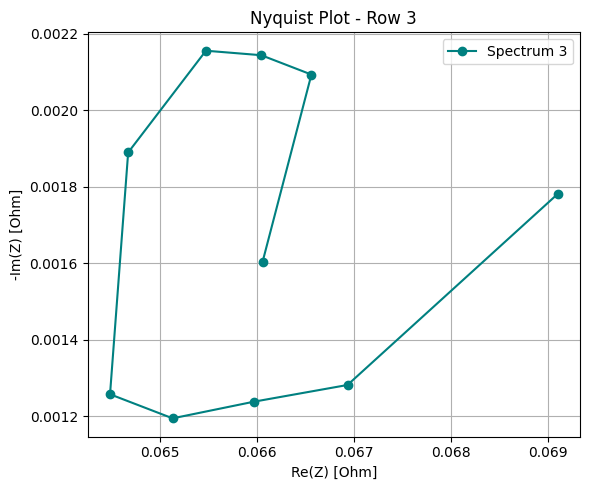

In [4]:
# Plot Nyquist for a specific row (e.g., row 10)
import matplotlib.pyplot as plt
index = 3  # Change this to plot any row
row = impedance_data.iloc[index]
re_z = [z.real for z in row]
im_z = [z.imag for z in row]
plt.figure(figsize=(6, 5))
plt.plot(re_z, [-y for y in im_z], 'o-', color='teal', label=f"Spectrum {index}")
plt.xlabel("Re(Z) [Ohm]")
plt.ylabel("-Im(Z) [Ohm]")
plt.title(f"Nyquist Plot - Row {index}")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [4]:
import pandas as pd
import numpy as np
from scipy.signal import savgol_filter
import matplotlib.pyplot as plt
import pickle

# ---------- Load the EIS Data ----------
df = pd.read_csv('EIS_Bat12.csv', header=None)

# ---------- Convert Strings to Complex ----------
def str_to_complex(s):
    s = s.replace('i', 'j')
    return complex(s)

impedance_data = df.applymap(str_to_complex)

# ---------- Apply Savitzky-Golay Filter ----------
filtered_impedance = []

for index, row in impedance_data.iterrows():
    re_z = np.array([z.real for z in row])
    im_z = np.array([z.imag for z in row])

    # Apply Savitzky-Golay (only if enough points)
    if len(re_z) >= 5:
        re_filtered = savgol_filter(re_z, window_length=5, polyorder=2)
        im_filtered = savgol_filter(im_z, window_length=5, polyorder=2)
    else:
        re_filtered = re_z
        im_filtered = im_z

    filtered_row = [complex(r, i) for r, i in zip(re_filtered, im_filtered)]
    filtered_impedance.append(filtered_row)

# ---------- Convert to DataFrame ----------
filtered_df = pd.DataFrame(filtered_impedance)

# ---------- Save Filtered Data ----------
with open("filtered_data.pkl", "wb") as f:
    pickle.dump(filtered_df, f)

print("✅ Filtered data saved as 'filtered_data.pkl'")

✅ Filtered data saved as 'filtered_data.pkl'


C:\Users\Hp\AppData\Local\Temp\ipykernel_14612\3617599220.py:15: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  impedance_data = df.applymap(str_to_complex)


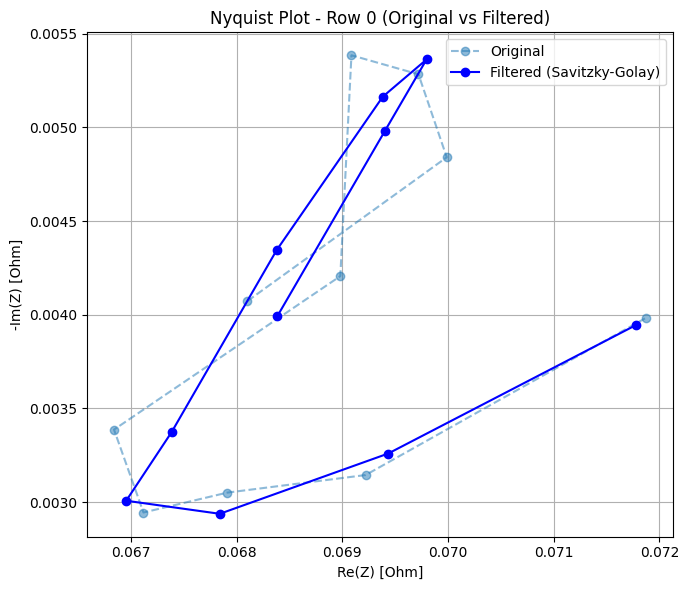

In [ ]:
# ---------- Visual Comparison ----------
row_idx = 2
original = impedance_data.iloc[row_idx]
filtered = filtered_df.iloc[row_idx]

re_orig = [z.real for z in original]
im_orig = [z.imag for z in original]

re_filt = [z.real for z in filtered]
im_filt = [z.imag for z in filtered]

plt.figure(figsize=(7,6))
plt.plot(re_orig, [-y for y in im_orig], 'o--', alpha=0.5, label="Original")
plt.plot(re_filt, [-y for y in im_filt], 'o-', color='blue', label="Filtered (Savitzky-Golay)")
plt.xlabel("Re(Z) [Ohm]")
plt.ylabel("-Im(Z) [Ohm]")
plt.title(f"Nyquist Plot - Row {row_idx} (Original vs Filtered)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

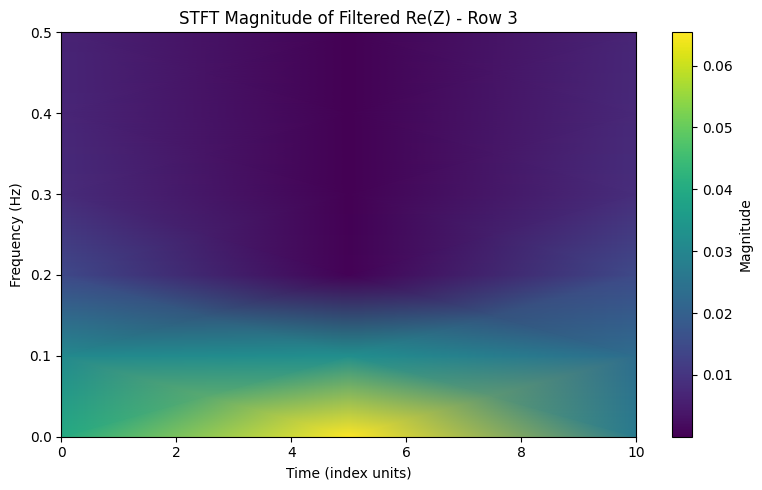

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft
import pickle

# ---------- Load Filtered Impedance Data ----------
with open("filtered_data.pkl", "rb") as f:
    filtered_df = pickle.load(f)

# ---------- Choose Row for STFT ----------
row_idx = 3  # Change for other spectra
row = filtered_df.iloc[row_idx]

# Extract filtered Re(Z)
re_z_filtered = np.array([z.real for z in row])

# ---------- Apply STFT ----------
frequencies, times, Zxx = stft(re_z_filtered, fs=1.0, nperseg=10)

# ---------- Plot STFT Magnitude Spectrogram ----------
plt.figure(figsize=(8, 5))
plt.pcolormesh(times, frequencies, np.abs(Zxx), shading='gouraud', cmap='viridis')
plt.title(f"STFT Magnitude of Filtered Re(Z) - Row {row_idx}")
plt.ylabel("Frequency (Hz)")
plt.xlabel("Time (index units)")
plt.colorbar(label='Magnitude')
plt.tight_layout()
plt.show()

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as la
from scipy.stats import skew, kurtosis

# --- Load your EIS dataset ---
df = pd.read_csv("EIS_Bat12.csv", header=None)

# Convert to complex numbers
def str_to_complex(s):
    s = s.replace('i', 'j')
    return complex(s)

impedance_data = df.applymap(str_to_complex)

# Estimated frequencies using C and Im(Z) method
C = 1.042e-6  # Farads (estimated)

C:\Users\Hp\AppData\Local\Temp\ipykernel_14612\2221079264.py:15: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  impedance_data = df.applymap(str_to_complex)


In [13]:
def compute_drt(frequencies, impedance, regularization_param=1e-3):
    z_real = np.real(impedance)
    z_imag = np.imag(impedance)

    n_points = len(frequencies)
    tau_max = 1 / np.min(frequencies)
    tau = np.logspace(-6, np.log10(tau_max), n_points)

    omega = 2 * np.pi * frequencies
    K_real = np.zeros((n_points, n_points))
    K_imag = np.zeros((n_points, n_points))

    for i in range(n_points):
        for j in range(n_points):
            K_real[i, j] = np.cos(omega[i] * tau[j]) / (1 + (omega[i] * tau[j])**2)
            K_imag[i, j] = np.sin(omega[i] * tau[j]) / (1 + (omega[i] * tau[j])**2)

    K = np.vstack((K_real, K_imag))
    Z = np.hstack([z_real, z_imag])

    G = la.solve(K.T @ K + regularization_param * np.eye(n_points), K.T @ Z)
    return tau, G

def extract_drt_features(tau, G):
    peak_idx = np.argmax(G)
    peak_tau = tau[peak_idx]
    peak_amplitude = G[peak_idx]
    peak_skewness = skew(G)
    peak_kurtosis = kurtosis(G)

    half_max = peak_amplitude / 2
    indices_above_half = np.where(G >= half_max)[0]
    width = tau[indices_above_half[-1]] - tau[indices_above_half[0]] if len(indices_above_half) > 1 else 0

    return {
        'peak_tau': peak_tau,
        'peak_amplitude': peak_amplitude,
        'peak_skewness': peak_skewness,
        'peak_kurtosis': peak_kurtosis,
        'width_half_max': width
    }

def extract_impedance_features(frequencies, impedance):
    z_real = np.real(impedance)
    z_imag = np.imag(impedance)
    transfer_resistance = z_real[0]
    diffusion_impedance = np.abs(impedance[-1])
    peak_idx = np.argmax(z_imag)
    peak_freq = frequencies[peak_idx]
    peak_skewness = skew(z_imag)
    kurt_val = kurtosis(z_imag)

    return {
        'transfer_resistance': transfer_resistance,
        'diffusion_impedance': diffusion_impedance,
        'peak_frequency': peak_freq,
        'imag_skewness': peak_skewness,
        'imag_kurtosis': kurt_val
    }

In [14]:
all_features = []

for idx, row in impedance_data.iterrows():
    impedance = np.array(row)
    Z_img = np.imag(impedance)
    Xc = np.abs(Z_img)
    frequency = 1 / (2 * np.pi * Xc * C)  # estimated frequency
    frequency = np.nan_to_num(frequency, nan=1.0, posinf=1.0, neginf=1.0)

    # Sort by frequency for proper DRT
    sort_idx = np.argsort(frequency)
    frequency_sorted = frequency[sort_idx]
    impedance_sorted = impedance[sort_idx]

    # DRT
    tau, G = compute_drt(frequency_sorted, impedance_sorted)
    drt_feat = extract_drt_features(tau, G)
    imp_feat = extract_impedance_features(frequency_sorted, impedance_sorted)

    combined = {
        "Row": idx+1,
        **drt_feat,
        **imp_feat
    }

    all_features.append(combined)

# Convert to DataFrame
features_df = pd.DataFrame(all_features)

# Save to CSV
features_df.to_csv("DRT_EIS_Combined_Features.csv", index=False)
print("Feature table saved as 'DRT_EIS_Combined_Features.csv'")

Feature table saved as 'DRT_EIS_Combined_Features.csv'


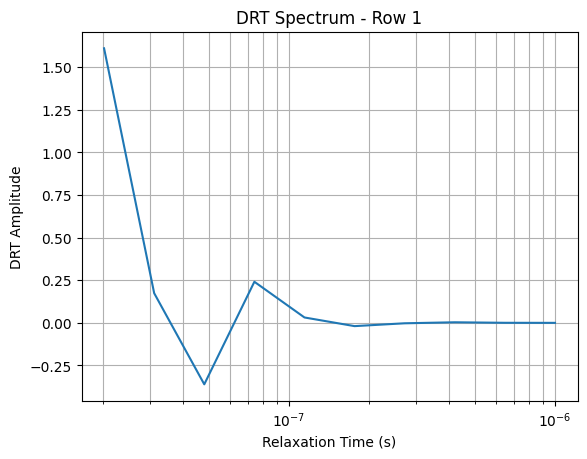

In [15]:
plt.semilogx(tau, G)
plt.xlabel("Relaxation Time (s)")
plt.ylabel("DRT Amplitude")
plt.title("DRT Spectrum - Row 1")
plt.grid(True, which="both")
plt.show()

C:\Users\Hp\AppData\Local\Temp\ipykernel_14612\2520367404.py:13: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  impedance_data = df.applymap(str_to_complex)


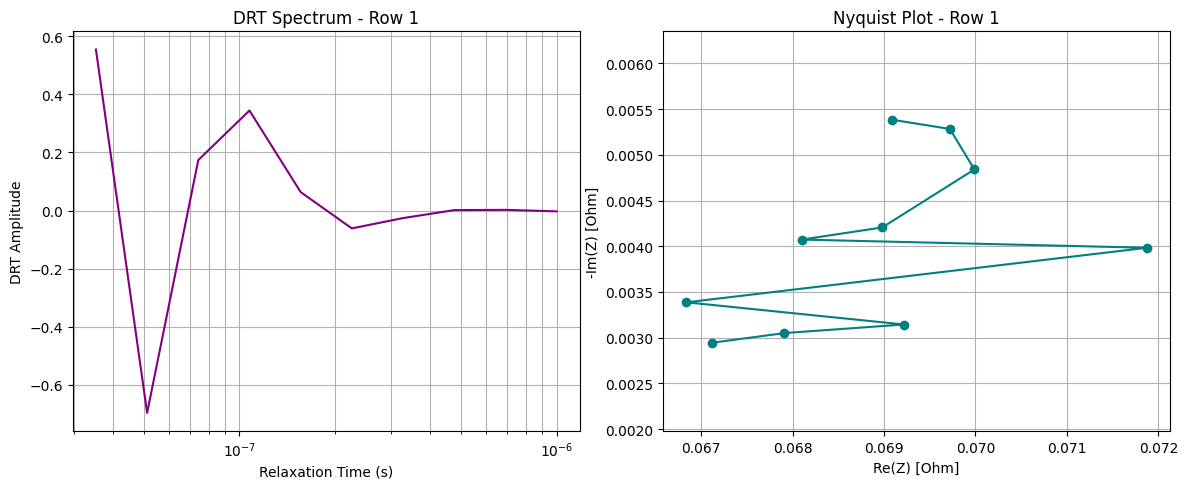

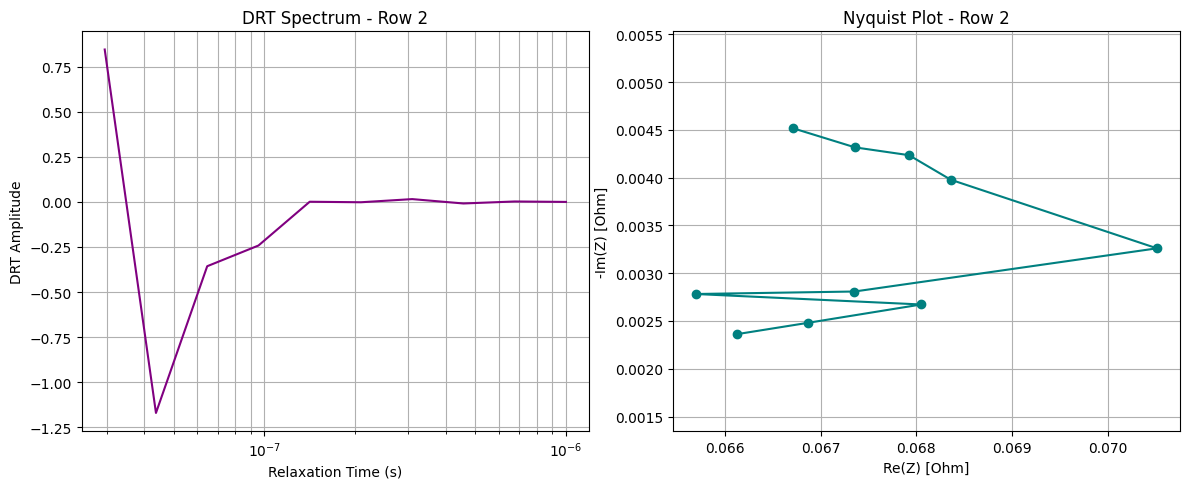

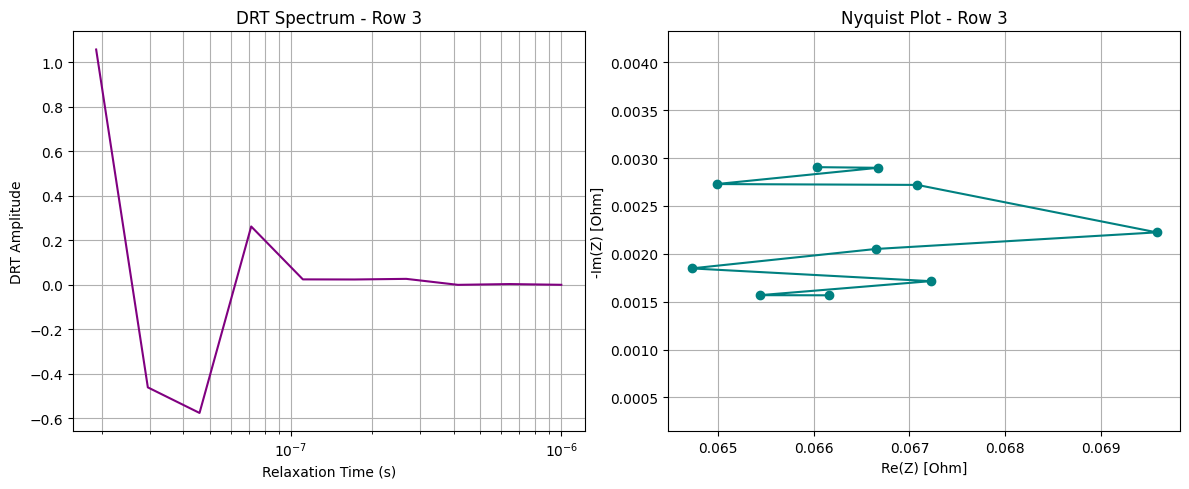

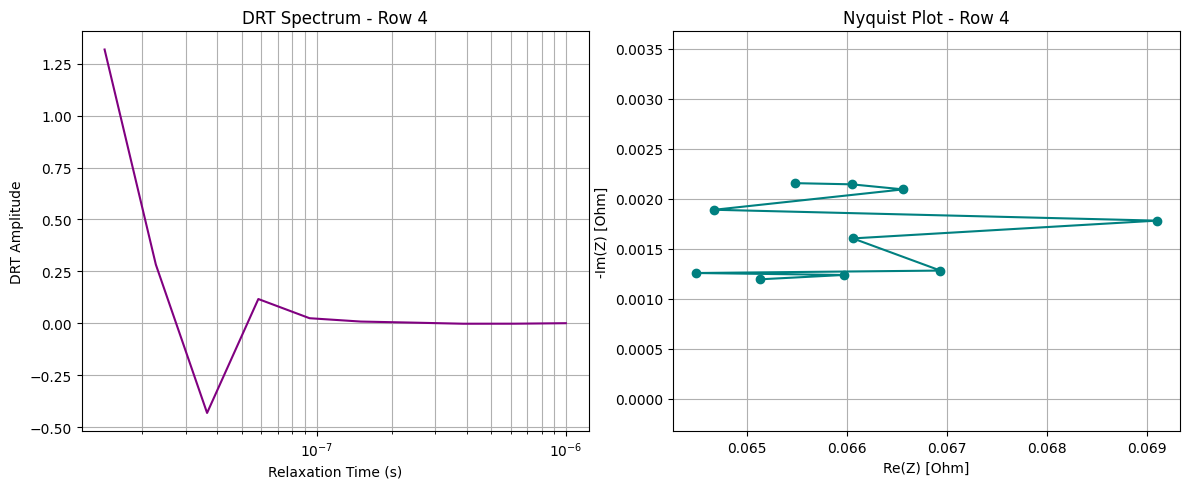

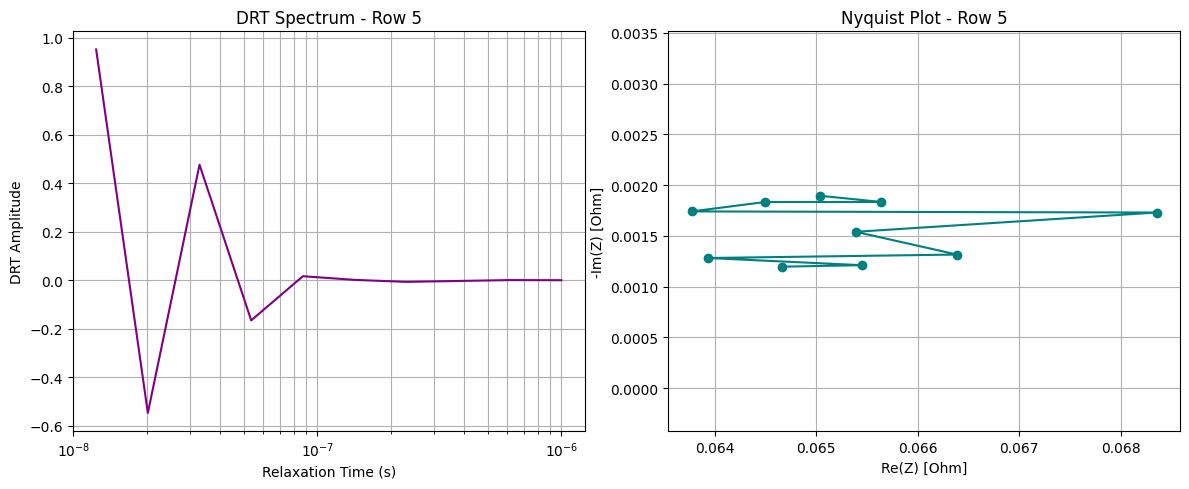

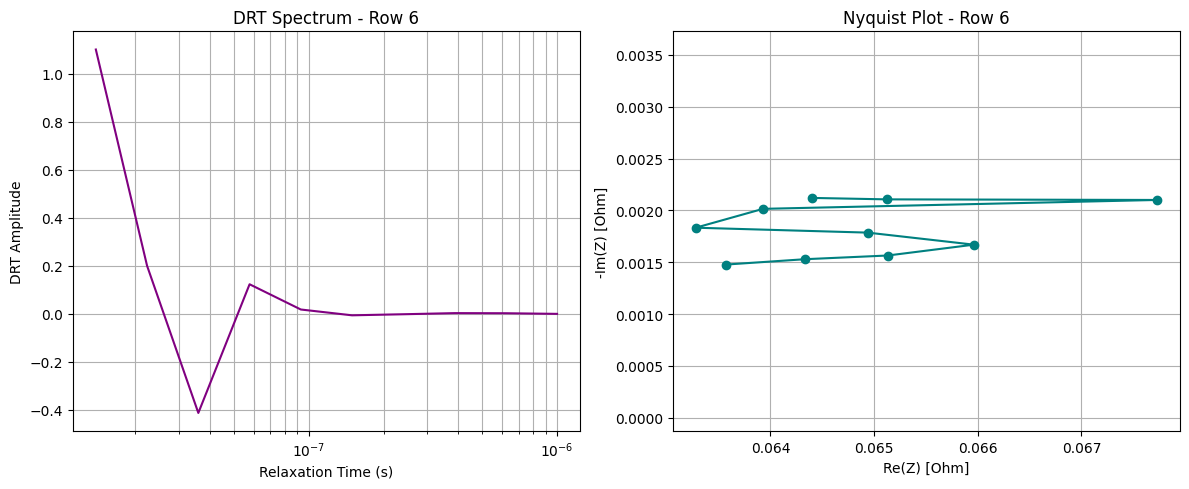

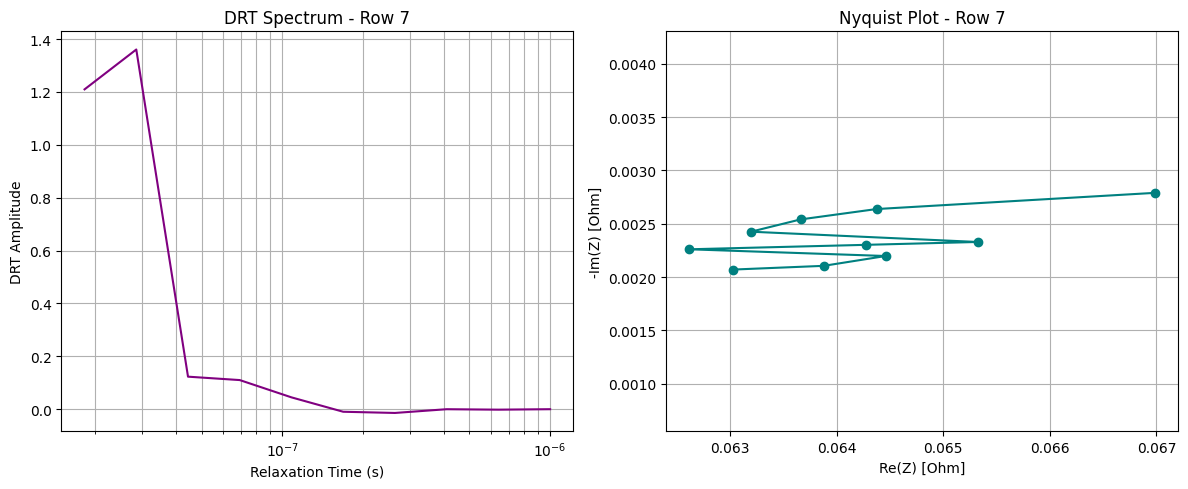

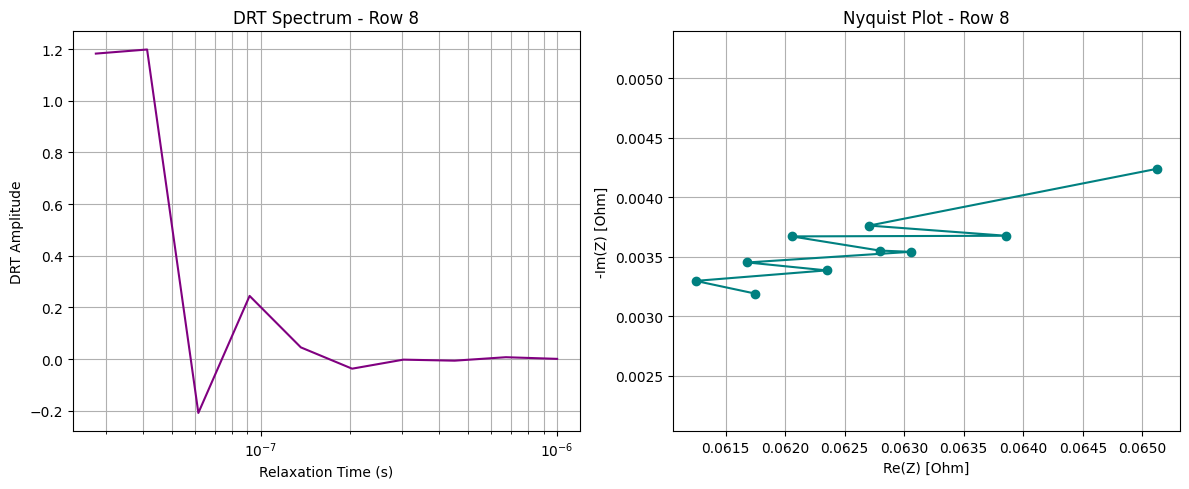

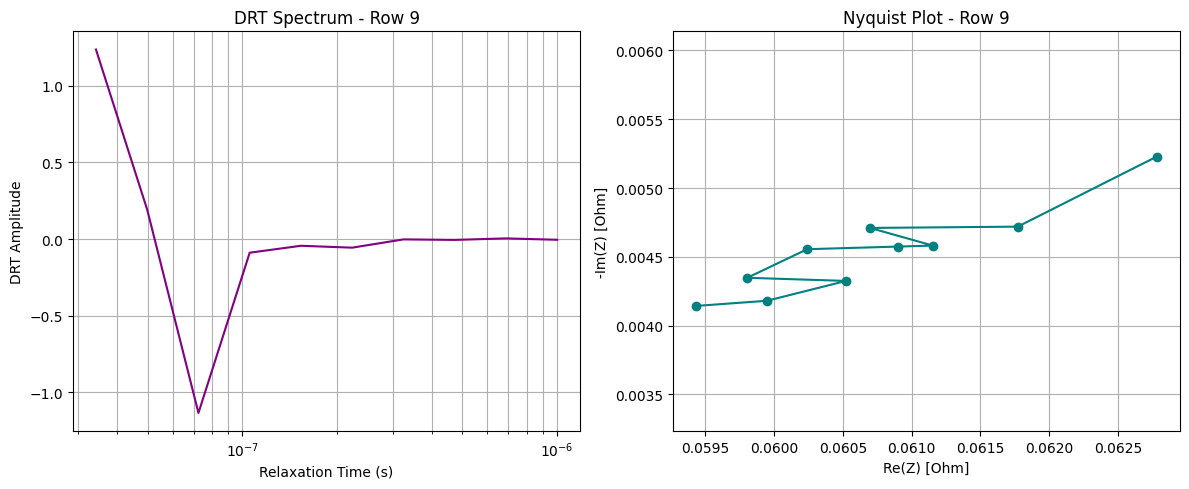

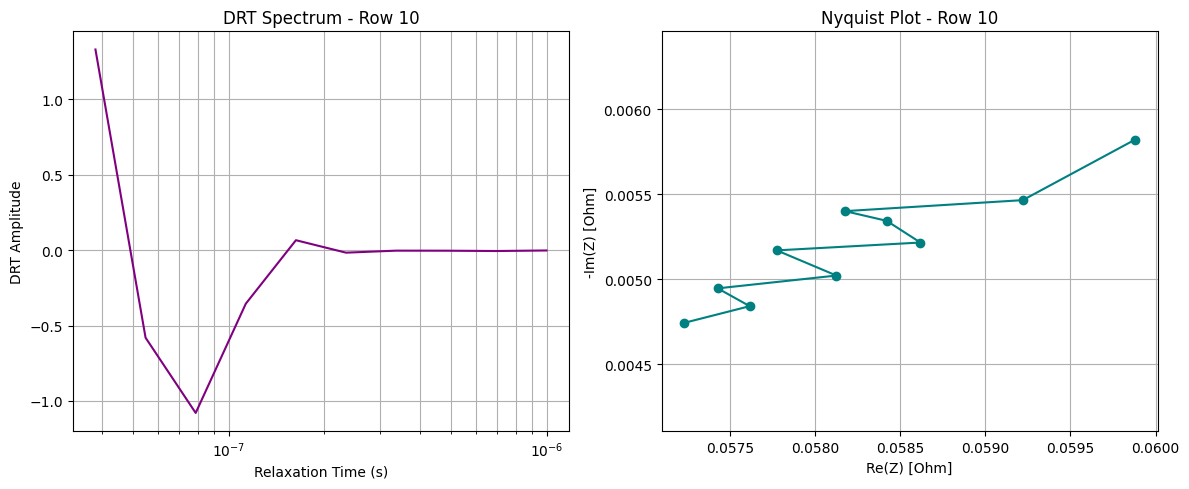

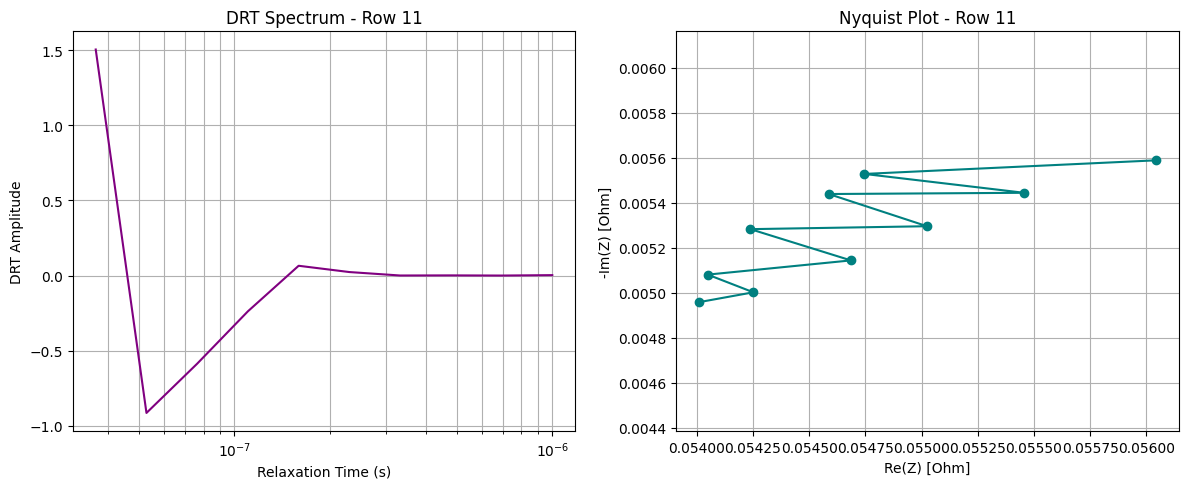

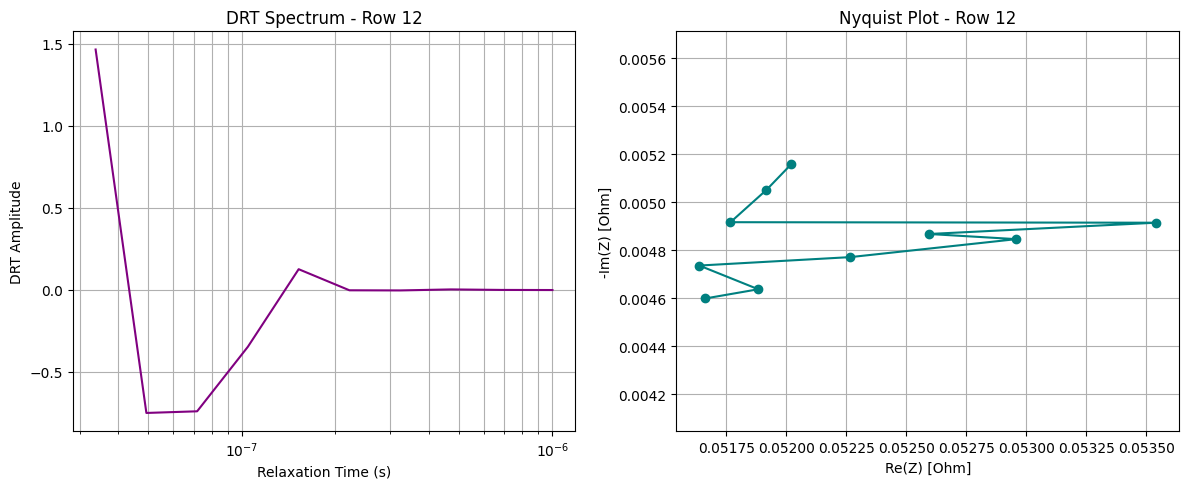

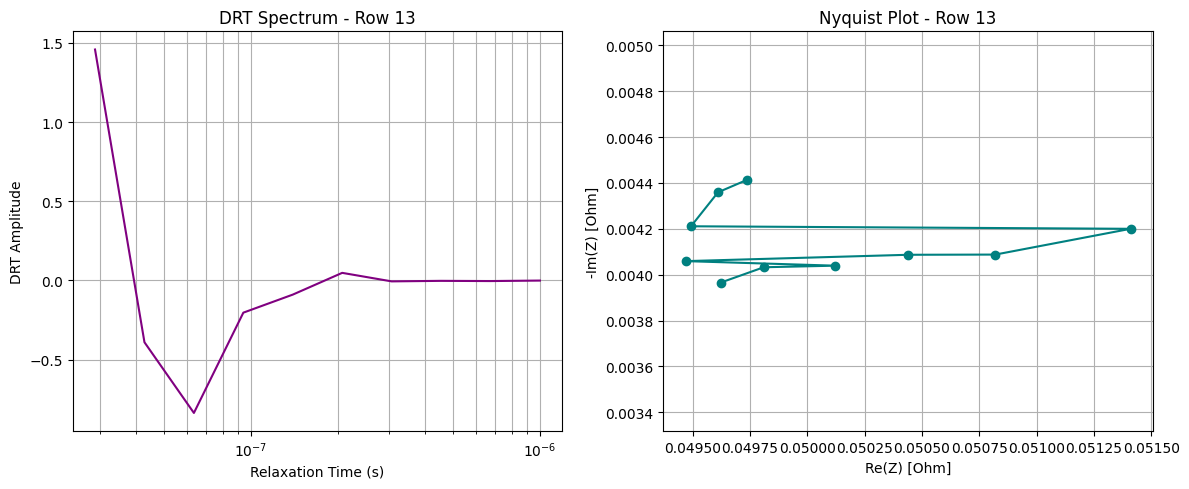

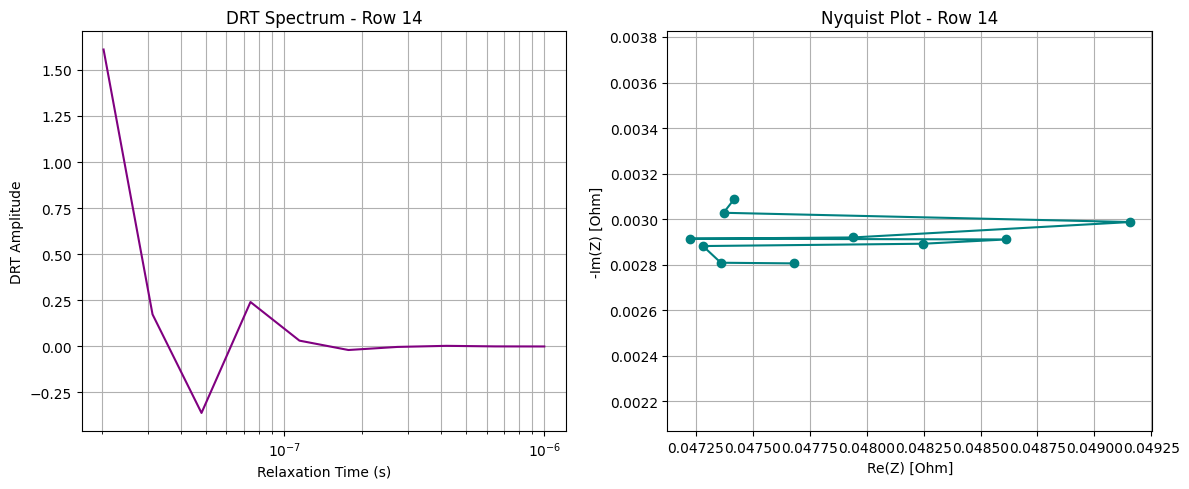

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as la
from scipy.stats import skew, kurtosis

# === Step 1: Load and convert dataset ===
df = pd.read_csv("EIS_Bat12.csv", header=None)

def str_to_complex(s):
    return complex(s.replace('i', 'j'))

impedance_data = df.applymap(str_to_complex)

# === Step 2: DRT and Nyquist functions ===
def compute_drt(frequencies, impedance, regularization_param=1e-3):
    z_real = np.real(impedance)
    z_imag = np.imag(impedance)
    n_points = len(frequencies)
    tau_max = 1 / np.min(frequencies)
    tau = np.logspace(-6, np.log10(tau_max), n_points)
    omega = 2 * np.pi * frequencies

    K_real = np.zeros((n_points, n_points))
    K_imag = np.zeros((n_points, n_points))
    for i in range(n_points):
        for j in range(n_points):
            K_real[i, j] = np.cos(omega[i] * tau[j]) / (1 + (omega[i] * tau[j])**2)
            K_imag[i, j] = np.sin(omega[i] * tau[j]) / (1 + (omega[i] * tau[j])**2)
    K = np.vstack((K_real, K_imag))
    Z = np.hstack([z_real, z_imag])
    G = la.solve(K.T @ K + regularization_param * np.eye(n_points), K.T @ Z)
    return tau, G

# === Step 3: Loop through each row and plot ===
C = 1.042e-6  # Capacitance

for idx, row in impedance_data.iterrows():
    impedance = np.array(row)
    Z_real = np.real(impedance)
    Z_imag = np.imag(impedance)

    # Estimate frequencies from imaginary impedance
    Xc = np.abs(Z_imag)
    frequency = 1 / (2 * np.pi * Xc * C)
    frequency = np.nan_to_num(frequency, nan=1.0, posinf=1.0, neginf=1.0)

    # Sort data by frequency
    sort_idx = np.argsort(frequency)
    freq_sorted = frequency[sort_idx]
    Z_sorted = impedance[sort_idx]
    Zr_sorted = np.real(Z_sorted)
    Zi_sorted = np.imag(Z_sorted)

    # Compute DRT
    tau, G = compute_drt(freq_sorted, Z_sorted)

    # === Plotting ===
    plt.figure(figsize=(12, 5))

    # Plot DRT Spectrum
    plt.subplot(1, 2, 1)
    plt.semilogx(tau, G, color='purple')
    plt.xlabel("Relaxation Time (s)")
    plt.ylabel("DRT Amplitude")
    plt.title(f"DRT Spectrum - Row {idx+1}")
    plt.grid(True, which="both")

    # Plot Nyquist
    plt.subplot(1, 2, 2)
    plt.plot(Zr_sorted, -Zi_sorted, 'o-', color='teal')
    plt.xlabel("Re(Z) [Ohm]")
    plt.ylabel("-Im(Z) [Ohm]")
    plt.title(f"Nyquist Plot - Row {idx+1}")
    plt.axis('equal')
    plt.grid(True)

    plt.tight_layout()
    plt.show()

    # Optional: Break early for testing
    # if idx > 3:
    #     break

In [1]:
import pandas as pd
import numpy as np
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler

# Step 1: Load data
df = pd.read_csv("EIS_Bat12.csv", header=None)
soc_levels = np.arange(10, 101, 10)

# Step 2: Select one frequency row
row_index = 0
Z_row = df.iloc[row_index]

features = []
labels = []

for col in range(Z_row.shape[0]):
    try:
        z = complex(str(Z_row[col]).replace("i", "j"))
        features.append([z.real, z.imag])  # Only Re(Z) and Im(Z)
        labels.append(soc_levels[col])
    except:
        continue

X = np.array(features)
y = np.array(labels)

# Step 3: Normalize features (MLPs need this)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 4: Train MLP Regressor
model = MLPRegressor(hidden_layer_sizes=(64, 32), activation='relu',
                     solver='adam', max_iter=2000, random_state=42)

model.fit(X_scaled, y)

# Step 5: Predict from your known Z input
z_input = complex("0.0612490952020785-0.00329710895055589j")  # Input impedance
X_input = np.array([[z_input.real, z_input.imag]])
X_input_scaled = scaler.transform(X_input)

predicted_soc = model.predict(X_input_scaled)
print(f"🔋 Predicted SoC for Z = {z_input}: {predicted_soc[0]:.2f}%")

# Step 6: Evaluate model
y_pred = model.predict(X_scaled)
print("MAE:", mean_absolute_error(y, y_pred))
print("R² Score:", r2_score(y, y_pred))

🔋 Predicted SoC for Z = (0.0612490952020785-0.00329710895055589j): 127.63%
MAE: 1.4775569768833647
R² Score: 0.9947602045914162


c:\Users\Hp\Downloads\Idea-Lab\env\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:780: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(
